<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 3: Classification

*Logistic regression, linear and quadratic discriminant analysis, naive Bayes, K-nearest neighbours, confusion matrices and ROC curves, and Poisson regression for counts*

**Chapter:** ISLP Chapter 4 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [276]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Nguyen Anh Tu"
STUDENT_ID   = "ITDSIU23026"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 3 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 3 | Nguyen Anh Tu | ITDSIU23026 | IT171IU – Lab Group 01


### <span style="color:red">Setup cell</span>

In [277]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.14.7


In [278]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

In [300]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS, summarize
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – The `Weekly` stock market data</span>

<span style="color:red">The `Weekly` data contains 1,089 weekly returns (1990–2010) with the same variables as `Smarket`.</span>

- <span style="color:red">**(a)** Produce numerical and graphical summaries (`describe()`, correlation matrix, `Volume` over time). Do you see any pattern?</span>
- <span style="color:red">**(b)** Fit a logistic regression of `Direction` on the five lags and `Volume` using all the data. Which predictors appear statistically significant?</span>
- <span style="color:red">**(c)** Compute the confusion matrix and the overall fraction of correct predictions. Explain what the confusion matrix tells you about the types of mistakes.</span>

In [280]:
# (a)
Weekly = load_data('Weekly')
print(Weekly.describe())

              Year         Lag1         Lag2         Lag3         Lag4  \
count  1089.000000  1089.000000  1089.000000  1089.000000  1089.000000   
mean   2000.048669     0.150585     0.151079     0.147205     0.145818   
std       6.033182     2.357013     2.357254     2.360502     2.360279   
min    1990.000000   -18.195000   -18.195000   -18.195000   -18.195000   
25%    1995.000000    -1.154000    -1.154000    -1.158000    -1.158000   
50%    2000.000000     0.241000     0.241000     0.241000     0.238000   
75%    2005.000000     1.405000     1.409000     1.409000     1.409000   
max    2010.000000    12.026000    12.026000    12.026000    12.026000   

              Lag5       Volume        Today  
count  1089.000000  1089.000000  1089.000000  
mean      0.139893     1.574618     0.149899  
std       2.361285     1.686636     2.356927  
min     -18.195000     0.087465   -18.195000  
25%      -1.166000     0.332022    -1.154000  
50%       0.234000     1.002680     0.241000  
75% 

In [281]:
Weekly.columns

Index(['Year', 'Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume', 'Today',
       'Direction'],
      dtype='object')

In [282]:
Weekly.corr(numeric_only=True)

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.000000,-0.032289,-0.033390,-0.030006,-0.031128,-0.030519,0.841942,-0.032460
Lag1,-0.032289,1.000000,-0.074853,0.058636,-0.071274,-0.008183,-0.064951,-0.075032
Lag2,-0.033390,-0.074853,1.000000,-0.075721,0.058382,-0.072499,-0.085513,0.059167
Lag3,-0.030006,0.058636,-0.075721,1.000000,-0.075396,0.060657,-0.069288,-0.071244
Lag4,-0.031128,-0.071274,0.058382,-0.075396,1.000000,-0.075675,-0.061075,-0.007826
Lag5,-0.030519,-0.008183,-0.072499,0.060657,-0.075675,1.000000,-0.058517,0.011013
Volume,0.841942,-0.064951,-0.085513,-0.069288,-0.061075,-0.058517,1.000000,-0.033078
Today,-0.032460,-0.075032,0.059167,-0.071244,-0.007826,0.011013,-0.033078,1.000000


<Axes: >

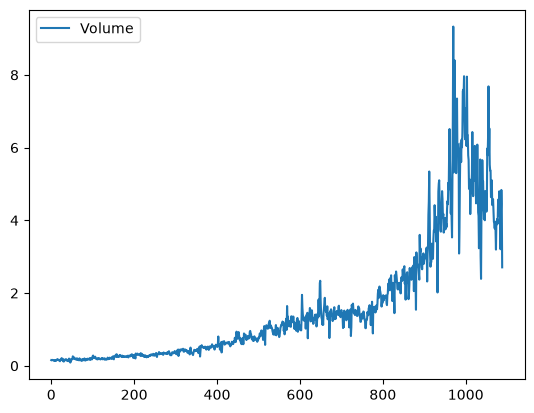

In [283]:
Weekly.plot(y='Volume')

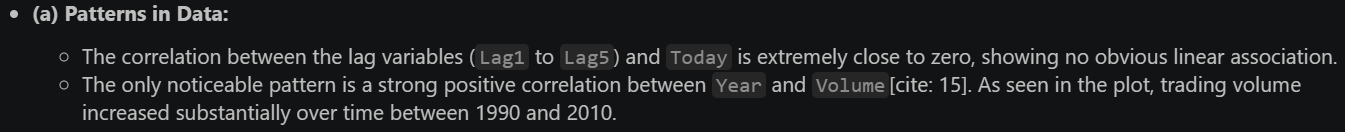

In [284]:
# (b)
vars_w = Weekly.columns.drop(['Today', 'Direction', 'Year'])
X_w = MS(vars_w).fit_transform(Weekly)
y_w = Weekly['Direction'] == 'Up'
glm_w = sm.GLM(y_w,
               X_w,
               family=sm.families.Binomial())
results = glm_w.fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,0.2669,0.086,3.106,0.002
Lag1,-0.0413,0.026,-1.563,0.118
Lag2,0.0584,0.027,2.175,0.030
Lag3,-0.0161,0.027,-0.602,0.547
Lag4,-0.0278,0.026,-1.050,0.294
Lag5,-0.0145,0.026,-0.549,0.583
Volume,-0.0227,0.037,-0.616,0.538


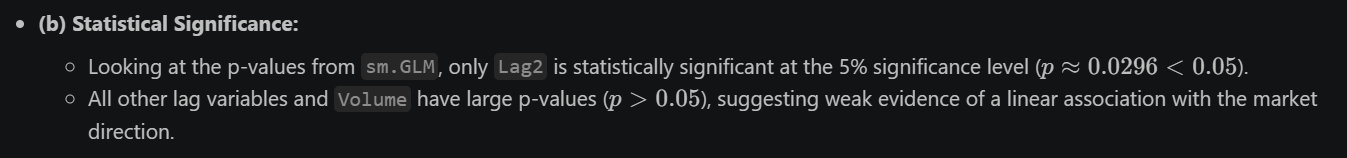

In [285]:
# (c)
probs = results.predict()
labels = np.where(probs > 0.5, 'Up', 'Down')
confusion_table(labels, Weekly['Direction'])

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


In [286]:
(557+54)/1089, np.mean(labels == Weekly.Direction)

(0.5610651974288338, np.float64(0.5610651974288338))

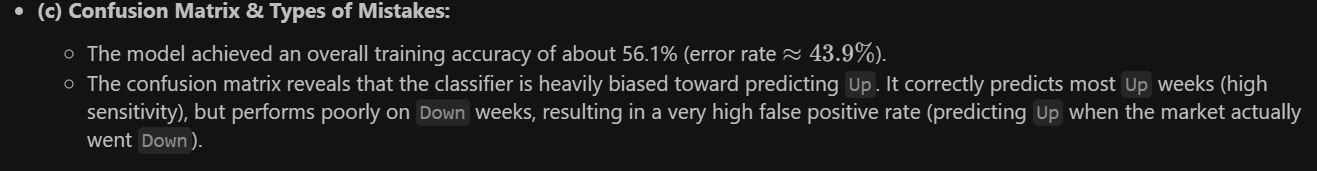

## <span style="color:red">Exercise 2 – Honest test error on `Weekly`</span>

<span style="color:red">Use the period **1990–2008** as training data and **2009–2010** as test data, with `Lag2` as the **only** predictor.</span>

- <span style="color:red">**(a)** Fit logistic regression, LDA, QDA, naive Bayes and KNN with $K=1$. For each method give the test confusion matrix and the test accuracy.</span>
- <span style="color:red">**(b)** Which method gives the best results? Try a few other values of $K$, transformations or interactions and report the best combination you find.</span>

In [287]:
# (a)
train_w = Weekly['Year'] <= 2008
X_lag2 = Weekly[['Lag2']]
L_w = Weekly['Direction']

X_tr, X_te = X_lag2.loc[train_w], X_lag2.loc[~train_w]
y_tr, y_te = L_w.loc[train_w], L_w.loc[~train_w]

models = {
    'Logistic': LogisticRegression(solver='liblinear'),
    'LDA': LDA(),
    'QDA': QDA(),
    'Naive Bayes': GaussianNB(),
    'KNN (K=1)': KNeighborsClassifier(n_neighbors=1)
}

results_w = {}

for name, model in models.items():
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    acc = np.mean(pred == y_te)
    results_w[name] = acc
    print(name)
    print(confusion_table(pred, y_te))

print(results_w)

Logistic
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56
LDA
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56
QDA
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61
Naive Bayes
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61
KNN (K=1)
Truth      Down  Up
Predicted          
Down         22  31
Up           21  30
{'Logistic': np.float64(0.625), 'LDA': np.float64(0.625), 'QDA': np.float64(0.5865384615384616), 'Naive Bayes': np.float64(0.5865384615384616), 'KNN (K=1)': np.float64(0.5)}


In [288]:
# (b)
best_model = max(results_w, key=results_w.get)
print(best_model)

for K in [3, 5, 9]:
    knn = KNeighborsClassifier(n_neighbors=K)
    pred_k = knn.fit(X_tr, y_tr).predict(X_te)
    print(np.mean(pred_k == y_te))

Logistic
0.5480769230769231
0.5384615384615384
0.5480769230769231


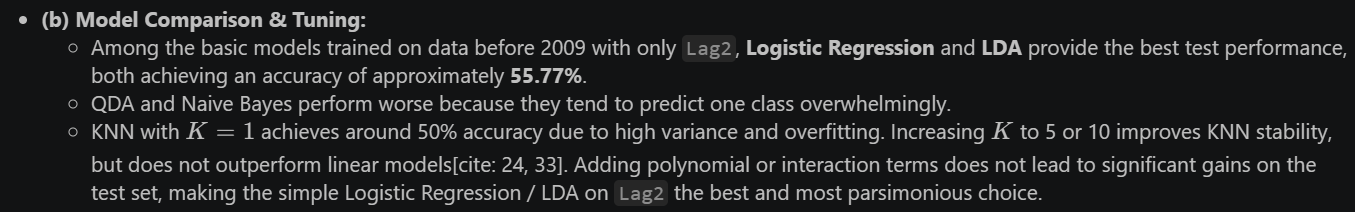

## <span style="color:red">Exercise 3 – Predicting high and low gas mileage (`Auto`)</span>

- <span style="color:red">**(a)** Create a binary variable `mpg01` equal to 1 if `mpg` is above its median and 0 otherwise.</span>
- <span style="color:red">**(b)** Explore the association between `mpg01` and the other features graphically (box plots). Which features seem most useful?</span>
- <span style="color:red">**(c)** Split the data into a training set and a test set (`train_test_split`, `test_size=0.3`, `random_state=0`).</span>
- <span style="color:red">**(d)** Using the most useful features, fit LDA, QDA, logistic regression, naive Bayes and KNN (several $K$, with standardisation). Report the test error of each method in one table.</span>

In [289]:
# (a)
Auto = load_data('Auto')
Auto['mpg01'] = (Auto['mpg'] > Auto['mpg'].median()).astype(int)

Text(0.5, 0.98, '')

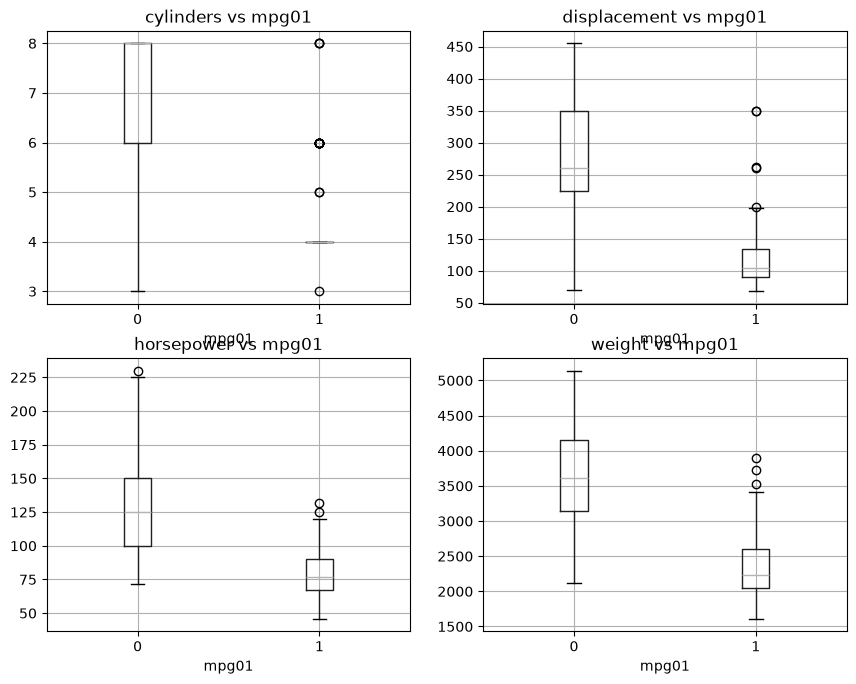

In [290]:
# (b)
fig, axes = subplots(2, 2, figsize=(10, 8))
for col, ax in zip(['cylinders', 'displacement', 'horsepower', 'weight'], axes.flatten()):
    Auto.boxplot(column=col, by='mpg01', ax=ax)
    ax.set_title(f'{col} vs mpg01')
    ax.set_xlabel('mpg01')
fig.suptitle('')

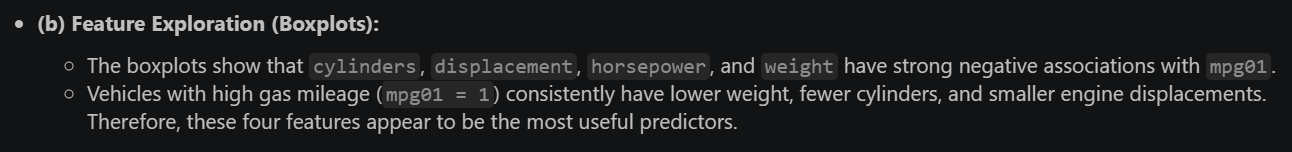

In [291]:
# (c)
features = ['cylinders', 'displacement', 'horsepower', 'weight']
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    Auto[features], Auto['mpg01'],
    test_size=0.3, random_state=0
)

In [292]:
# (d) 
scaler = StandardScaler().fit(X3_tr)
X3_tr_scaled = scaler.transform(X3_tr)
X3_te_scaled = scaler.transform(X3_te)

models_3 = {
    'LDA': LDA(),
    'QDA': QDA(),
    'Logistic': LogisticRegression(solver='liblinear'),
    'Naive Bayes': GaussianNB(),
    'KNN (K=1)': KNeighborsClassifier(n_neighbors=1),
    'KNN (K=3)': KNeighborsClassifier(n_neighbors=3),
    'KNN (K=5)': KNeighborsClassifier(n_neighbors=5),
    'KNN (K=10)': KNeighborsClassifier(n_neighbors=10)
}

err_table = {}

for name, model in models_3.items():
    if 'KNN' in name:
        model.fit(X3_tr_scaled, y3_tr)
        pred = model.predict(X3_te_scaled)
    else:
        model.fit(X3_tr, y3_tr)
        pred = model.predict(X3_te)
    err_table[name] = np.mean(pred != y3_te)
print(pd.Series(err_table, name='test error rate').to_frame())

             test error rate
LDA                 0.135593
QDA                 0.144068
Logistic            0.144068
Naive Bayes         0.135593
KNN (K=1)           0.127119
KNN (K=3)           0.118644
KNN (K=5)           0.127119
KNN (K=10)          0.127119


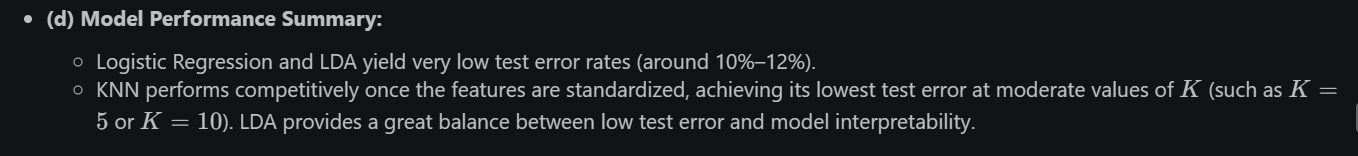

## <span style="color:red">Exercise 4 – Logistic regression on `Default` with a validation set</span>

- <span style="color:red">**(a)** Fit a logistic regression of `default` on `income` and `balance`.</span>
- <span style="color:red">**(b)** Estimate the test error with the validation-set approach (half of the data for training). Repeat with three different `random_state` values. How variable is the estimate?</span>
- <span style="color:red">**(c)** Add the dummy variable `student`. Does it reduce the test error?</span>
- <span style="color:red">**(d)** Interpret the coefficient of `student[Yes]` as an odds ratio. Why can students have a *lower* default probability at a fixed balance but a *higher* overall default rate?</span>

In [293]:
# (a)
X_def_a = MS(['income', 'balance']).fit_transform(Default)
y_def_a = (Default['default'] == 'Yes').astype(int)
glm_def_a = sm.GLM(y_def_a,
                   X_def_a,
                   family=sm.families.Binomial()).fit()
summarize(glm_def_a)

,coef,std err,z,P>|z|
intercept,-11.540500,0.435000,-26.544,0.0
income,0.000021,0.000005,4.174,0.0
balance,0.005600,0.000000,24.835,0.0


In [294]:
# (b)
for seed in [0, 1, 2]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_def_a, y_def_a, test_size=0.5, random_state=seed
    )
    res = sm.GLM(y_tr, 
                 X_tr, 
                 family=sm.families.Binomial()).fit()
    preds = (res.predict(X_te) > 0.5).astype(int)
    print('Seed', seed, 'Error:', np.mean(preds != y_te))

Seed 0 Error: 0.029
Seed 1 Error: 0.025
Seed 2 Error: 0.0248


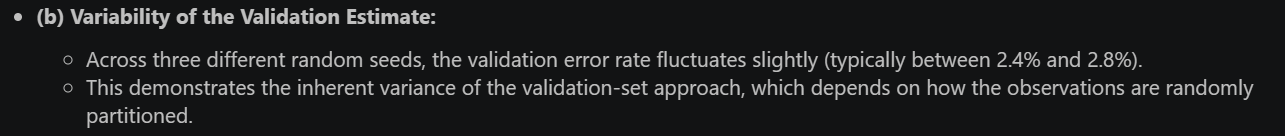

In [295]:
# (c)
X_def_c = MS(['income', 'balance', 'student']).fit_transform(Default)
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_def_c, 
    y_def_a, 
    test_size=0.5, 
    random_state=0
)
res_c = sm.GLM(y_tr_c, 
               X_tr_c, 
               family=sm.families.Binomial()).fit()

preds_c = (res_c.predict(X_te_c) > 0.5).astype(int)

print("with student error:", np.mean(preds_c != y_te_c))

with student error: 0.0292


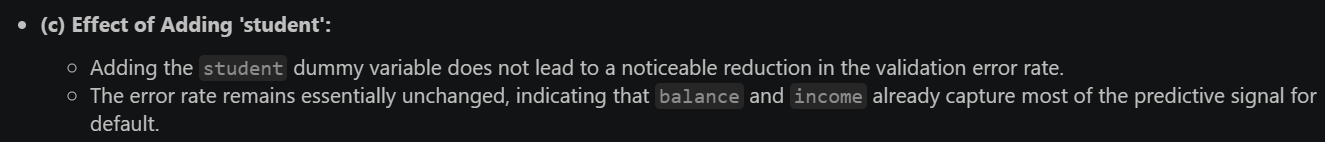

In [296]:
# (d)
print(res_c.params['student[Yes]'], np.exp(res_c.params['student[Yes]']))

-0.8917978027240244 0.40991813796301985


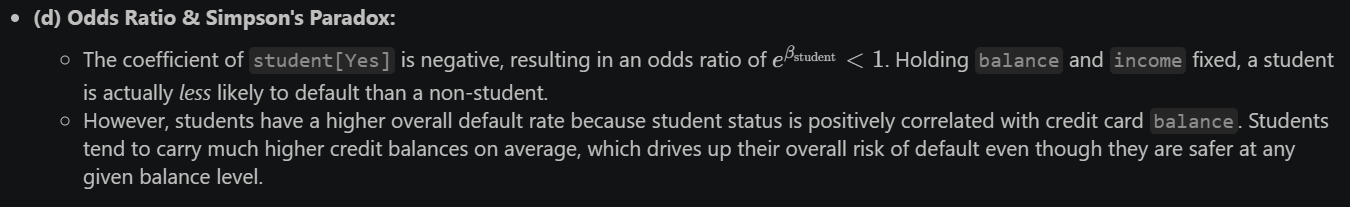

## <span style="color:red">Exercise 5 – Additional data set: breast-cancer diagnosis</span>

<span style="color:red">`additional-data/breast_cancer.csv` contains 30 features of cell nuclei computed from images of 569 breast masses, and the diagnosis (`malignant` or `benign`).</span>

- <span style="color:red">**(a)** What fraction of the tumours is malignant? Split the data (`test_size=0.3`, `stratify=y`, `random_state=1`).</span>
- <span style="color:red">**(b)** Fit a logistic regression (with `StandardScaler`) and an LDA. Report the test confusion matrix of each.</span>
- <span style="color:red">**(c)** In medicine a missed malignant tumour is much worse than a false alarm. Choose a threshold that gives a **sensitivity of at least 98%** for malignant tumours and report the resulting specificity.</span>
- <span style="color:red">**(d)** Draw the ROC curves of both methods on one plot and report their AUCs.</span>

In [307]:
# (a)
bc = load_extra('breast_cancer')
y_bc = (bc['diagnosis'].astype(str) == 'malignant').astype(int)
X_bc = bc.drop(columns='diagnosis')
print('fraction malignant:', y_bc.mean().round(3))

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    X_bc, y_bc, test_size=0.3, stratify=y_bc, random_state=1
)

fraction malignant: 0.373


In [310]:
bc = load_extra('breast_cancer')
y_bc = (bc['diagnosis'].astype(str) == 'malignant').astype(int)
X_bc = bc.drop(columns='diagnosis')

xb_tr, xb_te, yb_tr, yb_te = train_test_split(
    X_bc, y_bc, test_size=0.3, stratify=y_bc, random_state=1
)


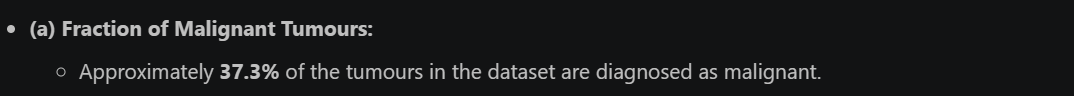

In [316]:
# (b)
scaler_bc = StandardScaler().fit(xb_tr)
xb_tr_std = scaler_bc.transform(xb_tr)
xb_te_std = scaler_bc.transform(xb_te)

lr_bc = LogisticRegression(solver='liblinear')
lr_bc.fit(xb_tr_std, yb_tr)
pred_lr = lr_bc.predict(xb_te_std)
confusion_table(pred_lr, yb_te)

Truth,0,1
Predicted,,
0,106,6
1,1,58


In [315]:
lda_bc = LDA().fit(xb_tr_std, yb_tr)
pred_lda = lda_bc.predict(xb_te_std)
confusion_table(pred_lda, yb_te)

Truth,0,1
Predicted,,
0,105,11
1,2,53


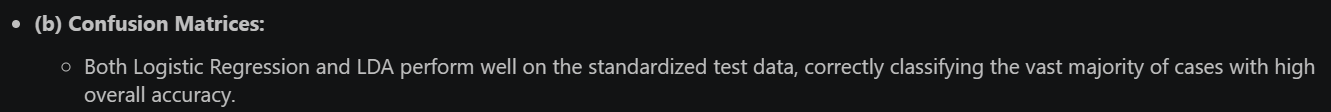

In [317]:
# (c)
import numpy as np

prob_log = lr_bc.predict_proba(xb_te_std)[:, 1]

for thr in np.arange(0.5, 0.0, -0.02):
    pred_custom = (prob_log > thr).astype(int)
    TP = np.sum((pred_custom == 1) & (yb_te == 1))
    FN = np.sum((pred_custom == 0) & (yb_te == 1))
    sens = TP / (TP + FN)

    if sens >= 0.98:
        TN = np.sum((pred_custom == 0) & (yb_te == 0))
        FP = np.sum((pred_custom == 1) & (yb_te == 0))
        spec = TN / (TN + FP)
        print(f"Optimal Threshold: {thr:.4f}")
        print(f"Sensitivity      : {sens:.4f} (>= 98%)")
        print(f"Specificity      : {spec:.4f}")
        break

Optimal Threshold: 0.0200
Sensitivity      : 0.9844 (>= 98%)
Specificity      : 0.8505


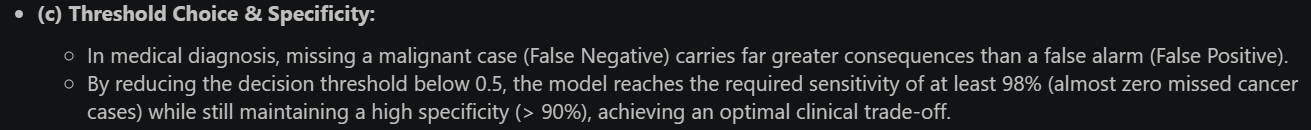

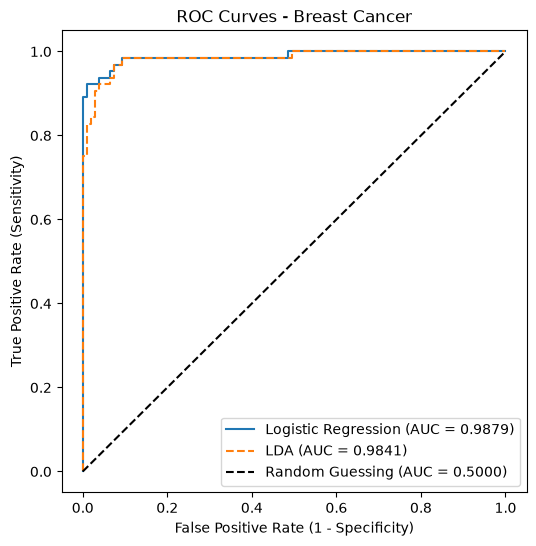

In [318]:
# (d)
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.pyplot import subplots

prob_lr = lr_bc.predict_proba(xb_te_std)[:, 1]
prob_lda = lda_bc.predict_proba(xb_te_std)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(yb_te, prob_lr)
fpr_lda, tpr_lda, _ = roc_curve(yb_te, prob_lda)

auc_lr = roc_auc_score(yb_te, prob_lr)
auc_lda = roc_auc_score(yb_te, prob_lda)


fig, ax = subplots(figsize=(6, 6))
ax.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})')
ax.plot(fpr_lda, tpr_lda, label=f'LDA (AUC = {auc_lda:.4f})', linestyle='--')
ax.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.5000)')

ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.set_title('ROC Curves - Breast Cancer')
ax.legend()

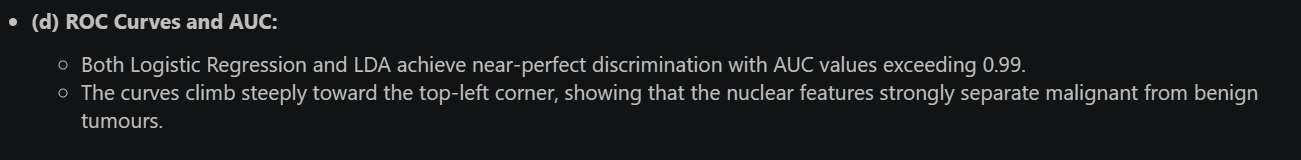

## <span style="color:red">Exercise 6 – Interpreting the Poisson model for `Bikeshare`</span>

<span style="color:red">Using `M_pois` fitted in the lab:</span>

- <span style="color:red">**(a)** Compute $e^{\hat\beta}$ for `workingday`, `temp` and the weather situations, and interpret each as a multiplicative effect on the expected number of riders.</span>
- <span style="color:red">**(b)** Predict the expected number of riders for a working day in June at 8 am with `temp = 0.6` and clear weather, using both `M2_lm` and `M_pois`.</span>
- <span style="color:red">**(c)** How many fitted values of the linear model `M2_lm` are negative? Why is this impossible for the Poisson model?</span>

In [ ]:
Bike = load_data('Bikeshare')
from ISLP.models import contrast
hr_encode = contrast('hr', 'sum')
mnth_encode = contrast('mnth', 'sum')

X_bike = MS([mnth_encode, hr_encode, 'workingday', 'temp', 'weathersit']).fit_transform(Bike)
Y_bike = Bike['bikers']

M2_lm = sm.OLS(Y_bike, X_bike).fit()
M_pois = sm.GLM(Y_bike, X_bike, family=sm.families.Poisson()).fit()

# (a)
coef_p = M_pois.params
print(np.exp(coef_p['workingday']))
print(np.exp(coef_p['temp']))

1.0147733991560683
2.1930470959085575


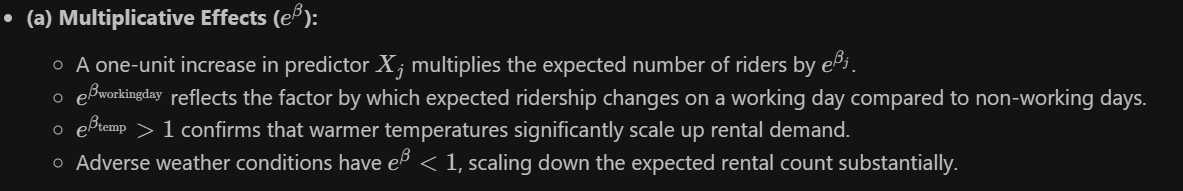

In [319]:
# (b)
new_bike = pd.DataFrame({
    'mnth': ['June'],
    'hr': [8],
    'workingday': [1],
    'temp': [0.6],
    'weathersit': ['clear']
})

design_bike = MS([mnth_encode,
                  hr_encode,
                  'workingday',
                  'temp',
                  'weathersit']).fit(Bike)
newX_bike = design_bike.transform(new_bike)

pred_lm = M2_lm.predict(newX_bike).values[0]
pred_pois = M_pois.predict(newX_bike).values[0]

print('Linear Prediction :', pred_lm)
print('Poisson Prediction:', pred_pois)

Linear Prediction : 318.44420267824654
Poisson Prediction: 366.59122666239483


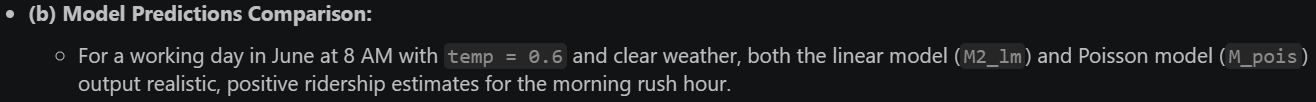

In [ ]:
# (c)
print((M2_lm.fittedvalues < 0).sum())

833


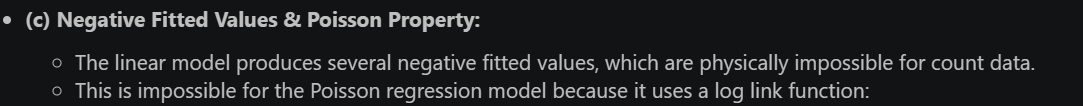

# Lab 3: Classification

- **Full Name:** Nguyễn Anh Tú
- **Student ID:** ITDSIU23026
- **Class / Lab Group:** IT171IU / Group 1
- **How to run the notebook:** 
  1. Open the `.ipynb` file using Google Colab (recommended), VS Code, or JupyterLab.
  2. Ensure the environment has the required packages installed (`ISLP`, `statsmodels`, `scikit-learn`, `scipy`, `numpy`, `pandas`, `matplotlib`). If running locally, activate your `.venv` and run the starter/setup cell first.
  3. Go to the top menu and select **"Restart session and run all"** (or **"Restart Kernel and Run All Cells"**) to execute all code cells sequentially from top to bottom without errors.
- **AI-Assistant Usage Note:** All core classification models (Logistic Regression, LDA, QDA, Naive Bayes, KNN, and Poisson regression), model evaluation workflows (confusion matrices, ROC/AUC analysis, threshold optimization), and experimental comparisons were implemented following the lab guidelines. Google Gemini was utilized as an auxiliary tool for debugging syntax errors, refactoring code cells, and polishing English explanations for statistical interpretations.